 Fase 1: Generación y Preparación de Datos


In [1]:
# ============================================================
# 1.1 CONFIGURAR EL ENTORNO
# ============================================================
import sys
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split

# Semilla para que los resultados sean reproducibles
SEED = 42
rng = np.random.default_rng(SEED)

# Estilo de las gráficas
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("Entorno listo")
print("-" * 35)
print(f"Python        : {sys.version.split()[0]}")
print(f"NumPy         : {np.__version__}")
print(f"SciPy         : {scipy.__version__}")
print(f"Matplotlib    : {matplotlib.__version__}")
print(f"Scikit-learn  : {sklearn.__version__}")
print(f"Semilla (SEED): {SEED}")

Entorno listo
-----------------------------------
Python        : 3.13.18
NumPy         : 2.4.6
SciPy         : 1.16.3
Matplotlib    : 3.10.0
Scikit-learn  : 1.6.1
Semilla (SEED): 42


In [2]:
# ============================================================
# 1.2 PARÁMETROS DE LA SEÑAL
# ============================================================
fs = 8000                    # Frecuencia de muestreo (Hz)
fc = 1000                    # Frecuencia portadora (Hz)
Rs = 100                     # Tasa de símbolos (baudios = símbolos/seg)

sps = int(fs / Rs)           # Muestras por símbolo (80)
NUM_SYMBOLS = 32             # Símbolos por señal generada
N_SAMPLES = NUM_SYMBOLS * sps  # Muestras totales por señal (2560)
DURACION = N_SAMPLES / fs    # Duración de cada señal (s)

f_dev = 300                  # Desviación de frecuencia para FSK (Hz)
f_FSK_0 = fc - f_dev         # Frecuencia para el bit 0 en FSK (700 Hz)
f_FSK_1 = fc + f_dev         # Frecuencia para el bit 1 en FSK (1300 Hz)

QAM_M = 16                   # Orden de la QAM (mínimo 16-QAM)

# Verificación del criterio de Nyquist: fs >= 2 * fmax
f_max = f_FSK_1 + Rs         # Frecuencia más alta aproximada de las señales
print("PARÁMETROS DE LA SEÑAL")
print("-" * 45)
print(f"Frecuencia de muestreo  fs : {fs} Hz")
print(f"Frecuencia portadora    fc : {fc} Hz")
print(f"Tasa de símbolos        Rs : {Rs} baudios")
print(f"Muestras por símbolo      : {sps}")
print(f"Símbolos por señal        : {NUM_SYMBOLS}")
print(f"Muestras por señal        : {N_SAMPLES}")
print(f"Duración por señal        : {DURACION*1000:.0f} ms")
print(f"FSK: bit 0 -> {f_FSK_0} Hz | bit 1 -> {f_FSK_1} Hz")
print(f"QAM: {QAM_M}-QAM ({int(np.log2(QAM_M))} bits por símbolo)")
print("-" * 45)
print(f"Nyquist: fs = {fs} Hz  >=  2*fmax = {2*f_max} Hz  ->",
      "CUMPLE" if fs >= 2 * f_max else "NO CUMPLE")

PARÁMETROS DE LA SEÑAL
---------------------------------------------
Frecuencia de muestreo  fs : 8000 Hz
Frecuencia portadora    fc : 1000 Hz
Tasa de símbolos        Rs : 100 baudios
Muestras por símbolo      : 80
Símbolos por señal        : 32
Muestras por señal        : 2560
Duración por señal        : 320 ms
FSK: bit 0 -> 700 Hz | bit 1 -> 1300 Hz
QAM: 16-QAM (4 bits por símbolo)
---------------------------------------------
Nyquist: fs = 8000 Hz  >=  2*fmax = 2800 Hz  -> CUMPLE


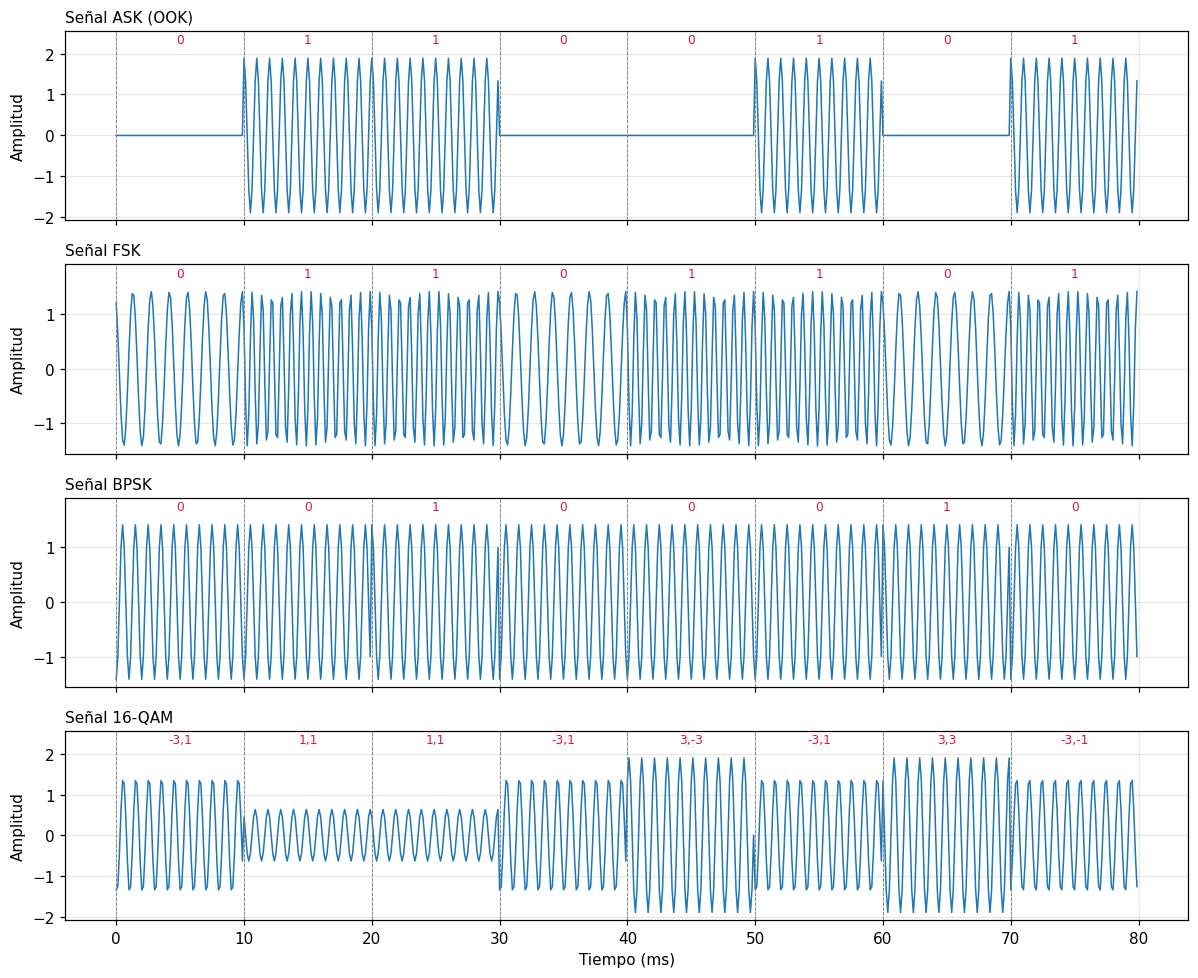

In [3]:
# ============================================================
# 1.3 GENERADORES DE SEÑALES
# Cada función devuelve: (señal, etiquetas_de_símbolos)
# Todas las señales se normalizan a potencia promedio = 1
# para que el SNR se defina igual en las 4 modulaciones.
# ============================================================
t = np.arange(N_SAMPLES) / fs          # Vector de tiempo


def normalizar_potencia(x):
    """Escala la señal para que su potencia promedio sea 1."""
    return x / np.sqrt(np.mean(x ** 2) + 1e-12)


def gen_ask():
    """ASK: bit 1 -> amplitud alta, bit 0 -> amplitud cero."""
    bits = rng.integers(0, 2, NUM_SYMBOLS)
    amplitud = np.repeat(bits, sps).astype(float)
    senal = amplitud * np.cos(2 * np.pi * fc * t)
    return normalizar_potencia(senal), [str(b) for b in bits]


def gen_fsk():
    """FSK: bit 1 -> frecuencia f1, bit 0 -> frecuencia f0 (fase continua)."""
    bits = rng.integers(0, 2, NUM_SYMBOLS)
    f_inst = np.repeat(np.where(bits == 1, f_FSK_1, f_FSK_0), sps)
    fase = 2 * np.pi * np.cumsum(f_inst) / fs   # Integral de la frecuencia
    senal = np.cos(fase)
    return normalizar_potencia(senal), [str(b) for b in bits]


def gen_psk():
    """BPSK: bit 1 -> fase 0°, bit 0 -> fase 180°."""
    bits = rng.integers(0, 2, NUM_SYMBOLS)
    fase_simbolo = np.where(bits == 1, 0.0, np.pi)
    fase = np.repeat(fase_simbolo, sps)
    senal = np.cos(2 * np.pi * fc * t + fase)
    return normalizar_potencia(senal), [str(b) for b in bits]


def gen_qam(M=QAM_M):
    """M-QAM cuadrada: amplitud (I) y fase (Q) combinadas."""
    L = int(np.sqrt(M))                       # Niveles por eje (4 para 16-QAM)
    niveles = np.arange(-(L - 1), L, 2)       # Ej. 16-QAM: [-3, -1, 1, 3]
    I = rng.choice(niveles, NUM_SYMBOLS)
    Q = rng.choice(niveles, NUM_SYMBOLS)
    I_t = np.repeat(I, sps)
    Q_t = np.repeat(Q, sps)
    senal = I_t * np.cos(2 * np.pi * fc * t) - Q_t * np.sin(2 * np.pi * fc * t)
    return normalizar_potencia(senal), [f"{i},{q}" for i, q in zip(I, Q)]


GENERADORES = {"ASK": gen_ask, "FSK": gen_fsk, "PSK": gen_psk, "QAM": gen_qam}
CLASES = list(GENERADORES.keys())


def graficar_ejemplos(n_simbolos=8):
    """Muestra un ejemplo de cada modulación (primeros n símbolos)."""
    n = n_simbolos * sps
    fig, ejes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
    nombres = {"ASK": "ASK (OOK)", "FSK": "FSK", "PSK": "BPSK",
               "QAM": f"{QAM_M}-QAM"}
    for ax, nombre in zip(ejes, CLASES):
        senal, etiquetas = GENERADORES[nombre]()
        ax.plot(t[:n] * 1000, senal[:n], lw=1)
        ax.set_ylabel("Amplitud")
        ax.set_title(f"Señal {nombres[nombre]}", loc="left", fontsize=10)
        ymax = np.max(np.abs(senal[:n])) * 1.35   # espacio extra para etiquetas
        ax.set_ylim(-np.max(np.abs(senal[:n])) * 1.1, ymax)
        for k in range(n_simbolos):
            ax.axvline(k * sps / fs * 1000, color="gray", ls="--", lw=0.6)
            ax.text((k + 0.5) * sps / fs * 1000, ymax * 0.98,
                    etiquetas[k], ha="center", va="top", fontsize=8,
                    color="crimson")
    ejes[-1].set_xlabel("Tiempo (ms)")
    plt.tight_layout()
    plt.show()


graficar_ejemplos()

DATASET LIMPIO (sin ruido)
---------------------------------------------
Forma de X : (4000, 2560)  (señales x muestras)
Forma de y : (4000,)
Tipo de dato de X: float32
Memoria usada    : 41.0 MB

Muestras por clase:
  0 -> ASK: 1000
  1 -> FSK: 1000
  2 -> PSK: 1000
  3 -> QAM: 1000

Archivo guardado: dataset_limpio.npz


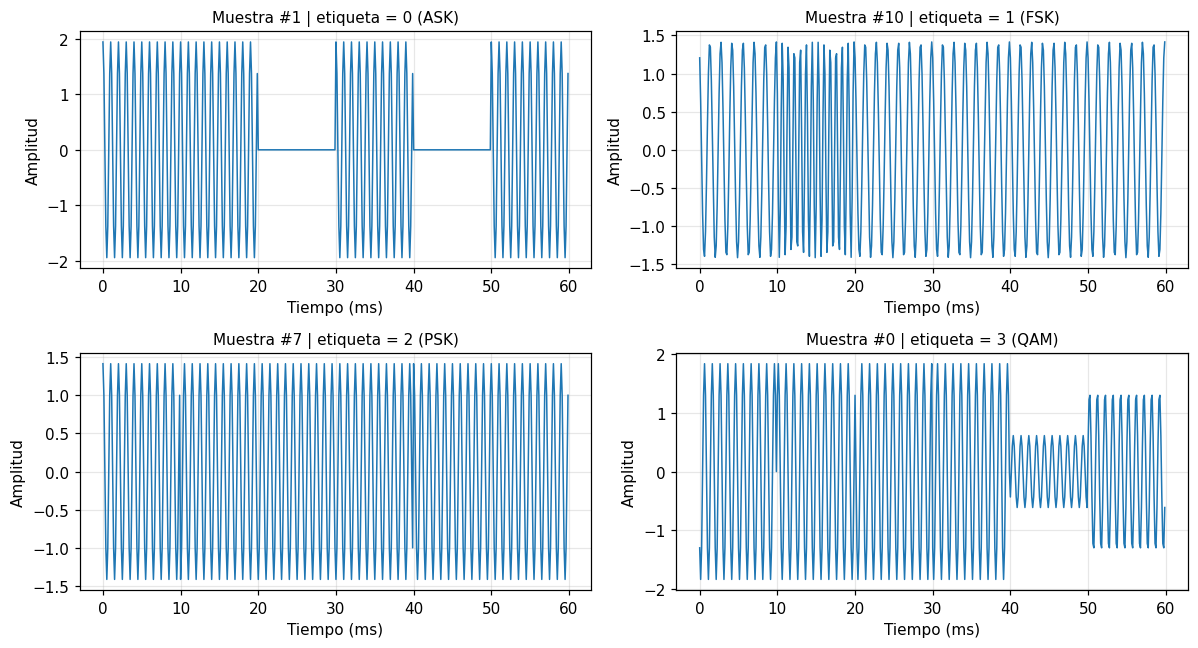

In [4]:
# ============================================================
# 1.4 GENERAR EL DATASET
# ============================================================
N_POR_CLASE = 1000   # Muestras por modulación (mínimo pedido: 1000)


def generar_dataset(n_por_clase):
    total = n_por_clase * len(CLASES)
    X = np.zeros((total, N_SAMPLES), dtype=np.float32)
    y = np.zeros(total, dtype=np.int64)
    k = 0
    for etiqueta, nombre in enumerate(CLASES):
        for _ in range(n_por_clase):
            senal, _ = GENERADORES[nombre]()
            X[k] = senal
            y[k] = etiqueta
            k += 1
    # Mezclar para que las clases no queden en bloques
    orden = rng.permutation(total)
    return X[orden], y[orden]


X_limpio, y = generar_dataset(N_POR_CLASE)

print("DATASET LIMPIO (sin ruido)")
print("-" * 45)
print(f"Forma de X : {X_limpio.shape}  (señales x muestras)")
print(f"Forma de y : {y.shape}")
print(f"Tipo de dato de X: {X_limpio.dtype}")
print(f"Memoria usada    : {X_limpio.nbytes / 1e6:.1f} MB")
print()
print("Muestras por clase:")
for idx, nombre in enumerate(CLASES):
    print(f"  {idx} -> {nombre}: {np.sum(y == idx)}")

# Guardar forma de onda + etiqueta
np.savez_compressed("dataset_limpio.npz", X=X_limpio, y=y,
                    clases=np.array(CLASES), fs=fs, fc=fc, Rs=Rs)
print("\nArchivo guardado: dataset_limpio.npz")

# Ejemplos tomados del dataset ya generado (una señal al azar por clase)
fig, ejes = plt.subplots(2, 2, figsize=(11, 6))
n_mostrar = 6 * sps
for idx, (ax, nombre) in enumerate(zip(ejes.ravel(), CLASES)):
    i = np.where(y == idx)[0][0]
    ax.plot(t[:n_mostrar] * 1000, X_limpio[i, :n_mostrar], lw=1)
    ax.set_title(f"Muestra #{i} | etiqueta = {idx} ({nombre})", fontsize=10)
    ax.set_xlabel("Tiempo (ms)")
    ax.set_ylabel("Amplitud")
plt.tight_layout()
plt.show()

VERIFICACIÓN DEL SNR
---------------------------------------------
SNR deseado =  0 dB | medido (prom.) = -0.00 dB | muestras = 800
SNR deseado =  5 dB | medido (prom.) =  5.01 dB | muestras = 800
SNR deseado = 10 dB | medido (prom.) = 10.00 dB | muestras = 800
SNR deseado = 15 dB | medido (prom.) = 15.01 dB | muestras = 800
SNR deseado = 20 dB | medido (prom.) = 20.00 dB | muestras = 800

Archivo guardado: dataset_ruidoso.npz


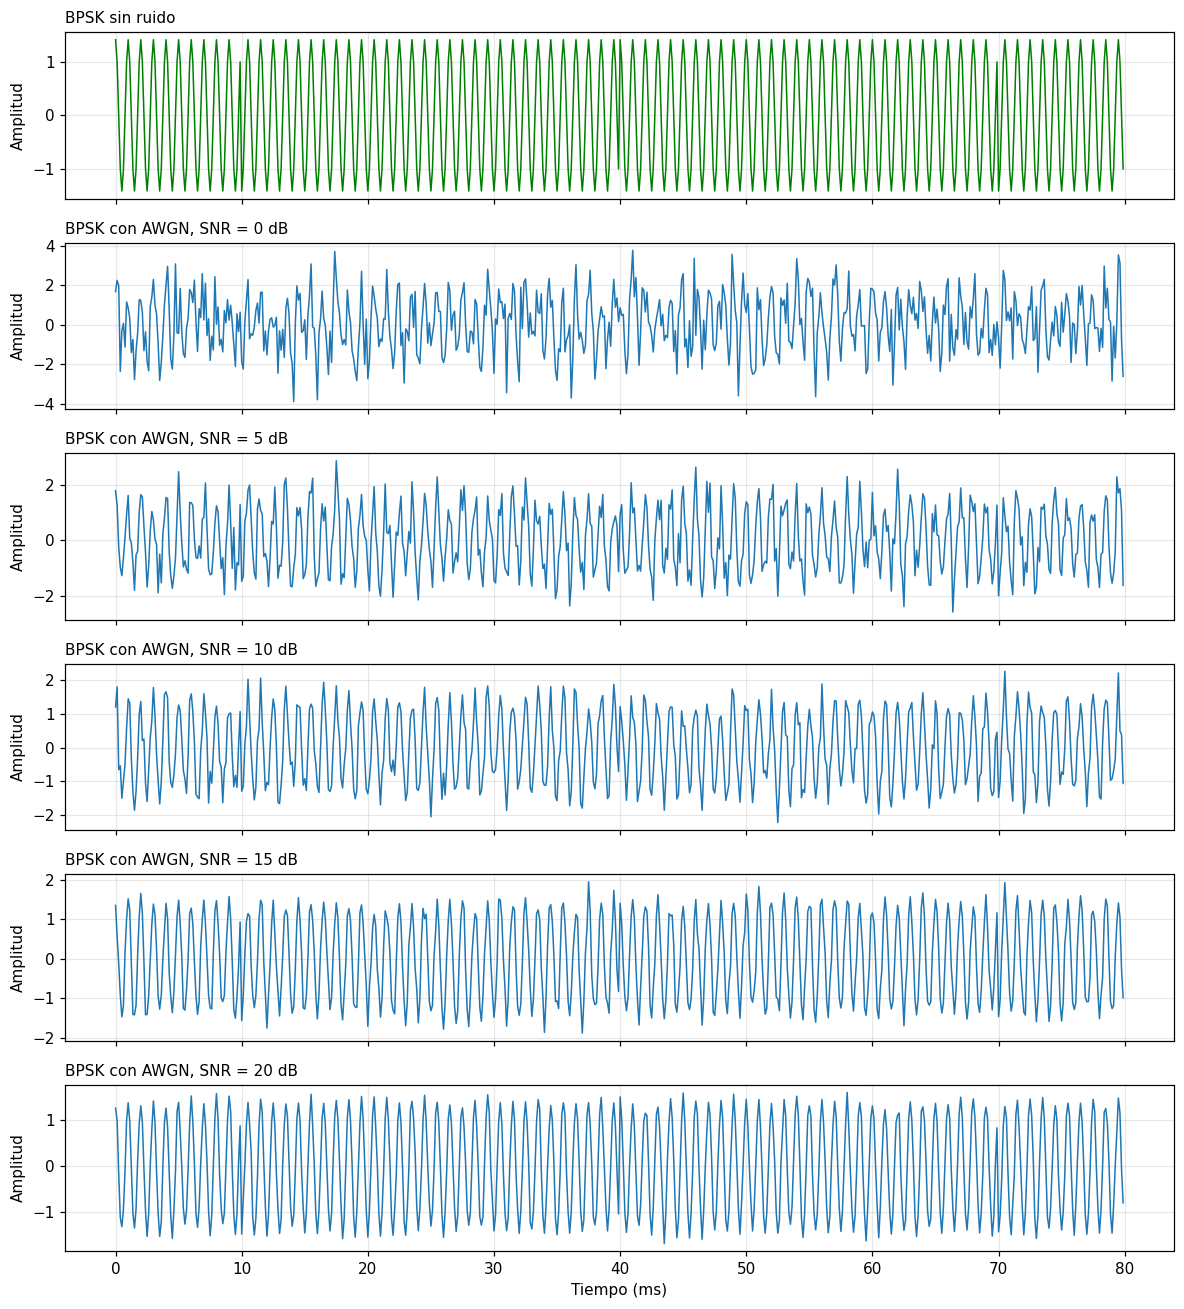

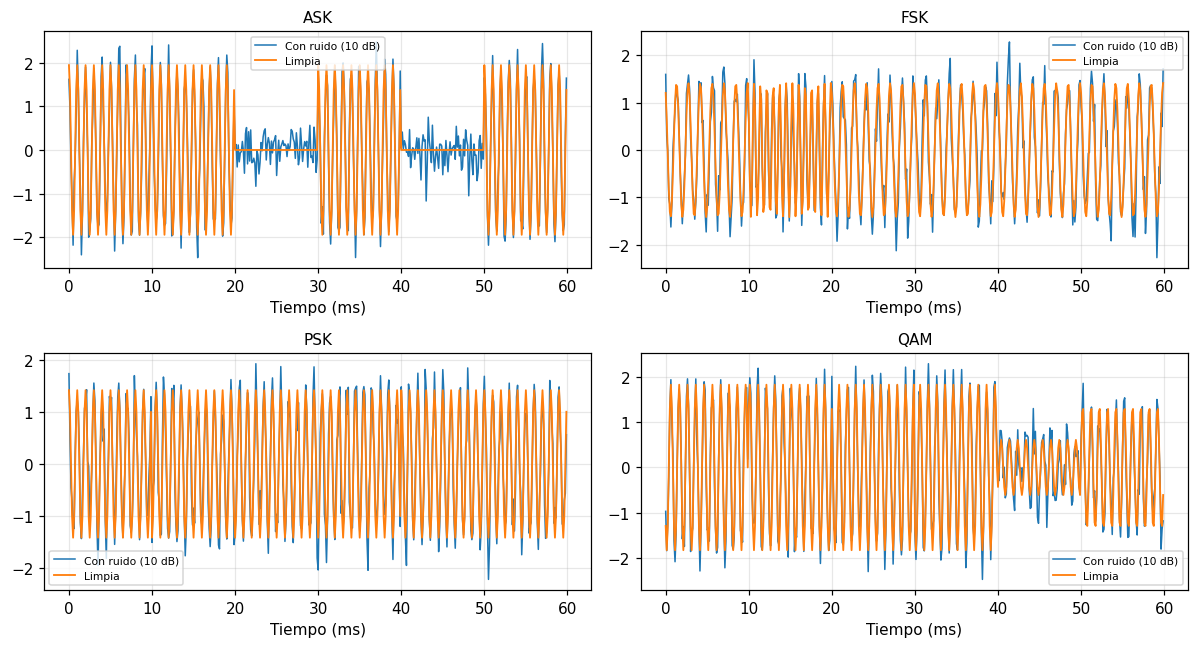

In [5]:
# ============================================================
# 1.5 RUIDO GAUSSIANO BLANCO ADITIVO (AWGN)
# SNR(dB) = 10 * log10( P_señal / P_ruido )
# ============================================================
SNR_LISTA = [0, 5, 10, 15, 20]   # Niveles de SNR en dB


def agregar_awgn(x, snr_db):
    """Suma ruido gaussiano a la señal x para obtener el SNR deseado (dB)."""
    x = x.astype(np.float64)
    p_senal = np.mean(x ** 2)
    p_ruido = p_senal / (10 ** (snr_db / 10))
    ruido = rng.normal(0.0, np.sqrt(p_ruido), size=x.shape)
    return (x + ruido).astype(np.float32)


# Asignar un SNR a cada señal de forma balanceada y mezclada
snr_por_muestra = np.resize(SNR_LISTA, len(y))     # repite la lista
snr_por_muestra = rng.permutation(snr_por_muestra)

X_ruidoso = np.zeros_like(X_limpio)
for i in range(len(y)):
    X_ruidoso[i] = agregar_awgn(X_limpio[i], snr_por_muestra[i])

# ---- Verificación: SNR medido vs SNR deseado ----
print("VERIFICACIÓN DEL SNR")
print("-" * 45)
for snr in SNR_LISTA:
    idx = np.where(snr_por_muestra == snr)[0][:200]
    medidos = []
    for i in idx:
        p_s = np.mean(X_limpio[i].astype(np.float64) ** 2)
        p_n = np.mean((X_ruidoso[i].astype(np.float64) - X_limpio[i]) ** 2)
        medidos.append(10 * np.log10(p_s / p_n))
    n_total = np.sum(snr_por_muestra == snr)
    print(f"SNR deseado = {snr:>2} dB | medido (prom.) = {np.mean(medidos):5.2f} dB | muestras = {n_total}")

np.savez_compressed("dataset_ruidoso.npz", X=X_ruidoso, y=y,
                    snr=snr_por_muestra, clases=np.array(CLASES))
print("\nArchivo guardado: dataset_ruidoso.npz")

# ---- Gráfica: la misma señal con distintos niveles de SNR ----
i_demo = np.where(y == CLASES.index("PSK"))[0][0]
senal_base = X_limpio[i_demo]
n_mostrar = 8 * sps

fig, ejes = plt.subplots(len(SNR_LISTA) + 1, 1,
                         figsize=(11, 2 * (len(SNR_LISTA) + 1)), sharex=True)
ejes[0].plot(t[:n_mostrar] * 1000, senal_base[:n_mostrar], lw=1, color="green")
ejes[0].set_title("BPSK sin ruido", loc="left", fontsize=10)
for ax, snr in zip(ejes[1:], SNR_LISTA):
    ruidosa = agregar_awgn(senal_base, snr)
    ax.plot(t[:n_mostrar] * 1000, ruidosa[:n_mostrar], lw=1)
    ax.set_title(f"BPSK con AWGN, SNR = {snr} dB", loc="left", fontsize=10)
for ax in ejes:
    ax.set_ylabel("Amplitud")
ejes[-1].set_xlabel("Tiempo (ms)")
plt.tight_layout()
plt.show()

# ---- Gráfica: las 4 modulaciones con SNR = 10 dB ----
fig, ejes = plt.subplots(2, 2, figsize=(11, 6))
for idx, (ax, nombre) in enumerate(zip(ejes.ravel(), CLASES)):
    i = np.where(y == idx)[0][0]
    ruidosa = agregar_awgn(X_limpio[i], 10)
    ax.plot(t[:6 * sps] * 1000, ruidosa[:6 * sps], lw=1, label="Con ruido (10 dB)")
    ax.plot(t[:6 * sps] * 1000, X_limpio[i, :6 * sps], lw=1.2, label="Limpia")
    ax.set_title(nombre, fontsize=10)
    ax.set_xlabel("Tiempo (ms)")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

SEPARACIÓN DEL DATASET
---------------------------------------------
Total de señales   : 4000
Entrenamiento (80%): 3200  ->  X_train (3200, 2560)
Prueba        (20%): 800  ->  X_test  (800, 2560)
Porcentaje real    : 80% / 20%

Señales por clase:
Clase      Train    Test
ASK          800     200
FSK          800     200
PSK          800     200
QAM          800     200

Señales por SNR (train / test):
   0 dB :  623 /  177
   5 dB :  641 /  159
  10 dB :  647 /  153
  15 dB :  636 /  164
  20 dB :  653 /  147

Archivo guardado: dataset_fase1_split.npz


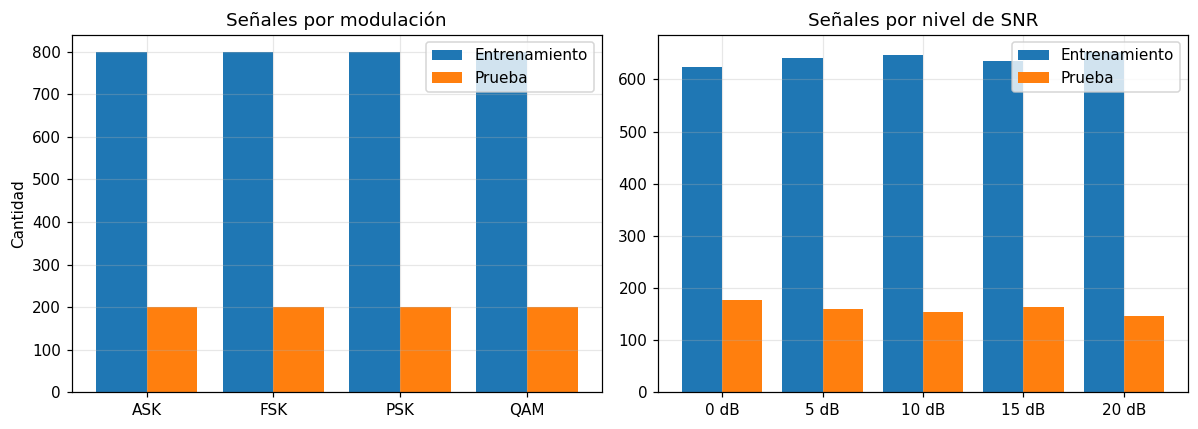

In [6]:
# ============================================================
# 1.6 SEPARACIÓN ENTRENAMIENTO (80%) / PRUEBA (20%)
# stratify=y mantiene la misma proporción de cada modulación
# en ambos grupos.
# ============================================================
X_train, X_test, y_train, y_test, snr_train, snr_test = train_test_split(
    X_ruidoso, y, snr_por_muestra,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

total = len(y)
print("SEPARACIÓN DEL DATASET")
print("-" * 45)
print(f"Total de señales   : {total}")
print(f"Entrenamiento (80%): {X_train.shape[0]}  ->  X_train {X_train.shape}")
print(f"Prueba        (20%): {X_test.shape[0]}  ->  X_test  {X_test.shape}")
print(f"Porcentaje real    : {100*len(y_train)/total:.0f}% / {100*len(y_test)/total:.0f}%")

print("\nSeñales por clase:")
print(f"{'Clase':<8}{'Train':>8}{'Test':>8}")
for idx, nombre in enumerate(CLASES):
    print(f"{nombre:<8}{np.sum(y_train == idx):>8}{np.sum(y_test == idx):>8}")

print("\nSeñales por SNR (train / test):")
for snr in SNR_LISTA:
    print(f"  {snr:>2} dB : {np.sum(snr_train == snr):>4} / {np.sum(snr_test == snr):>4}")

# Guardar todo para la Fase 2
np.savez_compressed("dataset_fase1_split.npz",
                    X_train=X_train, X_test=X_test,
                    y_train=y_train, y_test=y_test,
                    snr_train=snr_train, snr_test=snr_test,
                    clases=np.array(CLASES), fs=fs, fc=fc, Rs=Rs)
print("\nArchivo guardado: dataset_fase1_split.npz")

# ---- Gráfica de distribución ----
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
x_pos = np.arange(len(CLASES))
ejes[0].bar(x_pos - 0.2, [np.sum(y_train == i) for i in range(len(CLASES))],
            0.4, label="Entrenamiento")
ejes[0].bar(x_pos + 0.2, [np.sum(y_test == i) for i in range(len(CLASES))],
            0.4, label="Prueba")
ejes[0].set_xticks(x_pos)
ejes[0].set_xticklabels(CLASES)
ejes[0].set_title("Señales por modulación")
ejes[0].set_ylabel("Cantidad")
ejes[0].legend()

x_pos2 = np.arange(len(SNR_LISTA))
ejes[1].bar(x_pos2 - 0.2, [np.sum(snr_train == s) for s in SNR_LISTA], 0.4,
            label="Entrenamiento")
ejes[1].bar(x_pos2 + 0.2, [np.sum(snr_test == s) for s in SNR_LISTA], 0.4,
            label="Prueba")
ejes[1].set_xticks(x_pos2)
ejes[1].set_xticklabels([f"{s} dB" for s in SNR_LISTA])
ejes[1].set_title("Señales por nivel de SNR")
ejes[1].legend()
plt.tight_layout()
plt.show()

# (Opcional) Para no perder los archivos si Colab se reinicia:
# from google.colab import drive
# drive.mount('/content/drive')
# !cp dataset_*.npz /content/drive/MyDrive/

Fase 1 terminada
